In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.ticker import FuncFormatter

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = RAIZ / "data"
FIGURAS = RAIZ / "docs" / "latex" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

AZUL = "#2a78d6"
NARANJA = "#eb6834"
GRIS = "#b5b4ad"
TEXTO = "#0b0b0b"
TEXTO_2 = "#52514e"
REJILLA = "#e4e3de"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 220,
    "savefig.bbox": "tight",
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.edgecolor": REJILLA,
    "axes.labelcolor": TEXTO_2,
    "axes.titlecolor": TEXTO,
    "xtick.color": TEXTO_2,
    "ytick.color": TEXTO_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.color": REJILLA,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})

miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))

def guardar(fig, nombre):
    fig.savefig(FIGURAS / nombre, facecolor="white")
    plt.show()

In [2]:
crudo = pd.read_csv(DATOS / "crudos" / "mercadolibre_raw.csv", encoding="utf-8-sig", parse_dates=["fecha_extraccion"])
limpio = pd.read_csv(DATOS / "limpios" / "mercadolibre_limpio.csv", encoding="utf-8-sig", parse_dates=["fecha_extraccion"])
calidad = pd.read_csv(DATOS / "calidad" / "calidad_por_columna.csv", encoding="utf-8-sig")
diagnostico = pd.read_csv(DATOS / "calidad" / "diagnostico_columnas.csv", encoding="utf-8-sig")
revision = pd.read_csv(DATOS / "calidad" / "filas_para_revision.csv", encoding="utf-8-sig")
duplicados = pd.read_csv(DATOS / "calidad" / "duplicados_retirados.csv", encoding="utf-8-sig")
excluidos = pd.read_csv(DATOS / "calidad" / "precios_excluidos.csv", encoding="utf-8-sig")

assert len(crudo) == len(revision) + len(duplicados) + len(excluidos) + len(limpio)
len(crudo), len(revision), len(duplicados), len(excluidos), len(limpio)

(5080, 56, 605, 7, 4412)

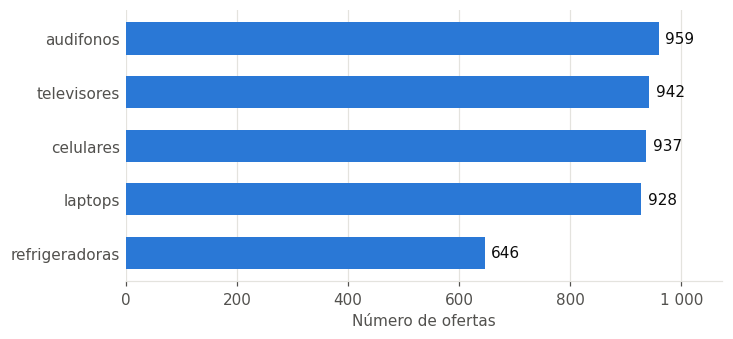

In [3]:
conteo = limpio["categoria"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(conteo.index, conteo.values, color=AZUL, height=0.6)
for y, v in enumerate(conteo.values):
    ax.text(v + 12, y, f"{v:,}".replace(",", " "), va="center", color=TEXTO, fontsize=10)
ax.set_xlabel("Número de ofertas")
ax.xaxis.set_major_formatter(miles)
ax.set_xlim(0, conteo.max() * 1.12)
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
guardar(fig, "registros_por_categoria.png")

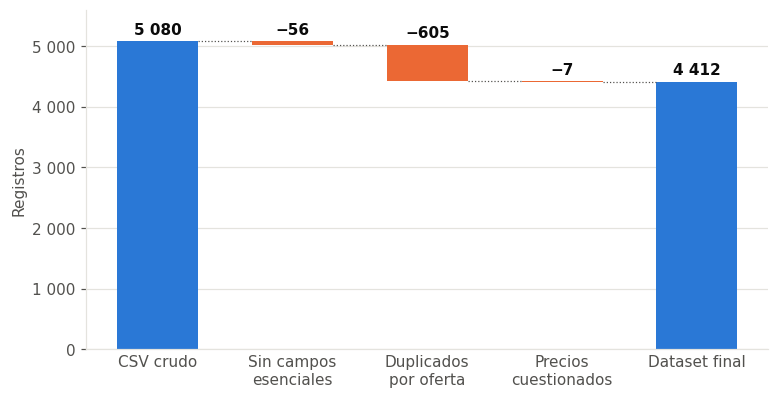

In [4]:
pasos = [
    ("CSV crudo", len(crudo), "total"),
    ("Sin campos\nesenciales", -len(revision), "resta"),
    ("Duplicados\npor oferta", -len(duplicados), "resta"),
    ("Precios\ncuestionados", -len(excluidos), "resta"),
    ("Dataset final", len(limpio), "total"),
]

fig, ax = plt.subplots(figsize=(8, 4))
nivel = 0
for i, (etiqueta, valor, tipo) in enumerate(pasos):
    if tipo == "total":
        base, alto, color = 0, valor, AZUL
        nivel = valor
        texto = f"{valor:,}".replace(",", " ")
    else:
        base, alto, color = nivel + valor, -valor, NARANJA
        nivel = nivel + valor
        texto = f"−{-valor:,}".replace(",", " ")
    ax.bar(i, alto, bottom=base, color=color, width=0.6)
    ax.text(i, base + alto + 70, texto, ha="center", va="bottom", color=TEXTO, fontsize=10, fontweight="bold")
    if i < len(pasos) - 1:
        ax.plot([i + 0.3, i + 0.7], [nivel, nivel], color=TEXTO_2, linewidth=0.8, linestyle=":")
ax.set_xticks(range(len(pasos)))
ax.set_xticklabels([p[0] for p in pasos])
ax.set_ylabel("Registros")
ax.yaxis.set_major_formatter(miles)
ax.set_ylim(0, len(crudo) * 1.1)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(axis="x", length=0)
guardar(fig, "embudo_limpieza.png")

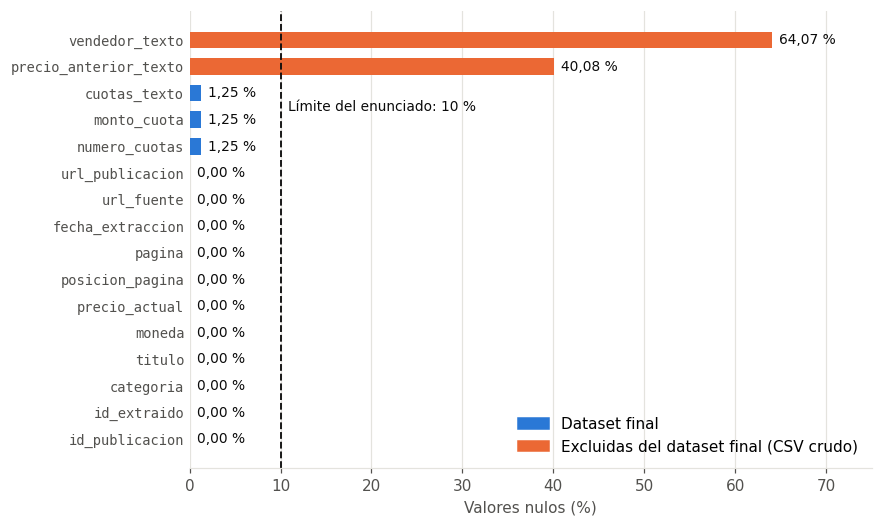

In [5]:
final = calidad[["variable", "porcentaje_nulos"]].assign(grupo="Dataset final")
retiradas = (diagnostico[diagnostico["columna"].isin(["precio_anterior_texto", "vendedor_texto"])]
             .rename(columns={"columna": "variable"})[["variable", "porcentaje_nulos"]]
             .assign(grupo="Excluidas del dataset final (CSV crudo)"))
nulos = pd.concat([final, retiradas]).sort_values("porcentaje_nulos").reset_index(drop=True)
colores = nulos["grupo"].map({"Dataset final": AZUL, "Excluidas del dataset final (CSV crudo)": NARANJA})

fig, ax = plt.subplots(figsize=(8, 5.4))
ax.barh(nulos["variable"], nulos["porcentaje_nulos"], color=colores, height=0.62)
for y, v in enumerate(nulos["porcentaje_nulos"]):
    ax.text(v + 0.8, y, f"{v:.2f} %".replace(".", ","), va="center", fontsize=9, color=TEXTO)
ax.axvline(10, color=TEXTO, linewidth=1.2, linestyle="--")
ax.text(10.8, len(nulos) - 3.5, "Límite del enunciado: 10 %", fontsize=9, color=TEXTO, va="center")
ax.set_xlabel("Valores nulos (%)")
ax.set_xlim(0, 75)
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
for lbl in ax.get_yticklabels():
    lbl.set_fontfamily("DejaVu Sans Mono")
    lbl.set_fontsize(9)
handles = [plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=NARANJA)]
ax.legend(handles, ["Dataset final", "Excluidas del dataset final (CSV crudo)"], loc="lower right")
guardar(fig, "nulos_por_columna.png")

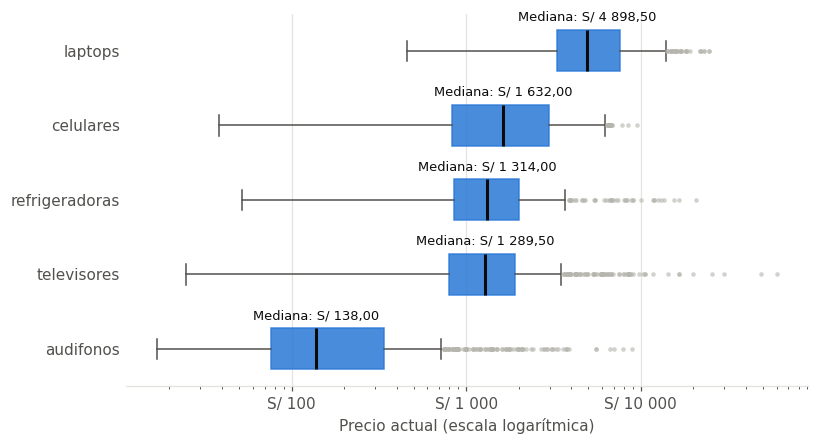

In [6]:
orden = limpio.groupby("categoria")["precio_actual"].median().sort_values().index
grupos = [limpio.loc[limpio["categoria"] == c, "precio_actual"] for c in orden]

fig, ax = plt.subplots(figsize=(8, 4.4))
bp = ax.boxplot(grupos, vert=False, widths=0.55, patch_artist=True,
                medianprops=dict(color=TEXTO, linewidth=2),
                boxprops=dict(facecolor=AZUL, edgecolor=AZUL, alpha=0.85),
                whiskerprops=dict(color=TEXTO_2, linewidth=1),
                capprops=dict(color=TEXTO_2, linewidth=1),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.6))
ax.set_yticks(range(1, len(orden) + 1))
ax.set_yticklabels(orden)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"S/ {x:,.0f}".replace(",", " ")))
for y, g in enumerate(grupos, start=1):
    m = g.median()
    ax.text(m, y + 0.36, f"Mediana: S/ {m:,.2f}".replace(",", "X").replace(".", ",").replace("X", " "),
            ha="center", va="bottom", fontsize=8.5, color=TEXTO)
ax.set_xlabel("Precio actual (escala logarítmica)")
ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
guardar(fig, "boxplot_precios_categoria.png")

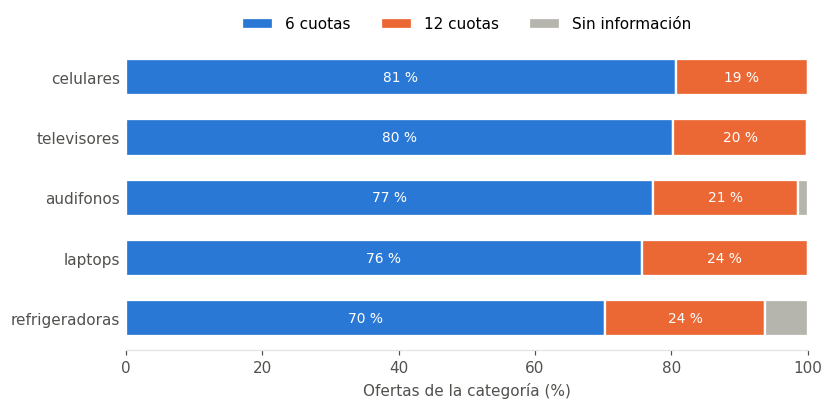

In [7]:
tabla = (limpio.assign(cuotas=limpio["numero_cuotas"].map({6: "6 cuotas", 12: "12 cuotas"}).fillna("Sin información"))
         .pivot_table(index="categoria", columns="cuotas", values="id_publicacion", aggfunc="count", fill_value=0))
tabla = tabla[["6 cuotas", "12 cuotas", "Sin información"]]
porc = tabla.div(tabla.sum(axis=1), axis=0) * 100
porc = porc.loc[porc["6 cuotas"].sort_values().index]
colores_cuotas = {"6 cuotas": AZUL, "12 cuotas": NARANJA, "Sin información": GRIS}

fig, ax = plt.subplots(figsize=(8, 3.6))
izquierda = np.zeros(len(porc))
for col in porc.columns:
    ax.barh(porc.index, porc[col], left=izquierda, color=colores_cuotas[col], height=0.6,
            edgecolor="white", linewidth=1.5, label=col)
    for y, (x0, w) in enumerate(zip(izquierda, porc[col])):
        if w >= 8:
            ax.text(x0 + w / 2, y, f"{w:.0f} %", ha="center", va="center", fontsize=9,
                    color="white" if col != "Sin información" else TEXTO)
    izquierda += porc[col].values
ax.set_xlim(0, 100)
ax.set_xlabel("Ofertas de la categoría (%)")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
guardar(fig, "cuotas_por_categoria.png")

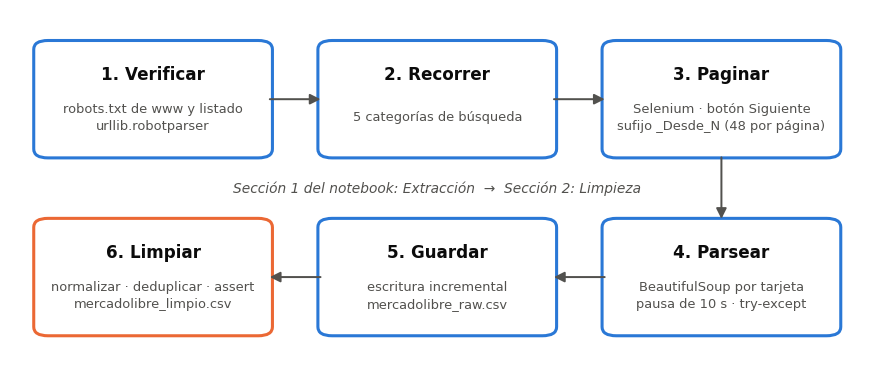

In [8]:
pasos_flujo = [
    ("1. Verificar", "robots.txt de www y listado\nurllib.robotparser"),
    ("2. Recorrer", "5 categorías de búsqueda"),
    ("3. Paginar", "Selenium · botón Siguiente\nsufijo _Desde_N (48 por página)"),
    ("4. Parsear", "BeautifulSoup por tarjeta\npausa de 10 s · try-except"),
    ("5. Guardar", "escritura incremental\nmercadolibre_raw.csv"),
    ("6. Limpiar", "normalizar · deduplicar · assert\nmercadolibre_limpio.csv"),
]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.set_xlim(0, 3)
ax.set_ylim(0, 2)
ax.axis("off")
posiciones = [(0.5, 1.5), (1.5, 1.5), (2.5, 1.5), (2.5, 0.5), (1.5, 0.5), (0.5, 0.5)]
ancho, alto = 0.8, 0.62
for (titulo, detalle), (cx, cy), i in zip(pasos_flujo, posiciones, range(6)):
    color = NARANJA if i == 5 else AZUL
    caja = FancyBboxPatch((cx - ancho / 2, cy - alto / 2), ancho, alto,
                          boxstyle="round,pad=0.02,rounding_size=0.05",
                          facecolor="white", edgecolor=color, linewidth=2)
    ax.add_patch(caja)
    ax.text(cx, cy + 0.14, titulo, ha="center", va="center", fontsize=11, fontweight="bold", color=TEXTO)
    ax.text(cx, cy - 0.1, detalle, ha="center", va="center", fontsize=8.5, color=TEXTO_2, linespacing=1.4)
for (x0, y0), (x1, y1) in zip(posiciones[:-1], posiciones[1:]):
    if y0 == y1:
        ini = (x0 + ancho / 2 * (1 if x1 > x0 else -1), y0)
        fin = (x1 - ancho / 2 * (1 if x1 > x0 else -1), y1)
    else:
        ini, fin = (x0, y0 - alto / 2), (x1, y1 + alto / 2)
    ax.add_patch(FancyArrowPatch(ini, fin, arrowstyle="-|>", mutation_scale=14, color=TEXTO_2, linewidth=1.3))
ax.text(1.5, 1.0, "Sección 1 del notebook: Extracción  →  Sección 2: Limpieza",
        ha="center", va="center", fontsize=9, color=TEXTO_2, style="italic")
guardar(fig, "pipeline_extraccion.png")

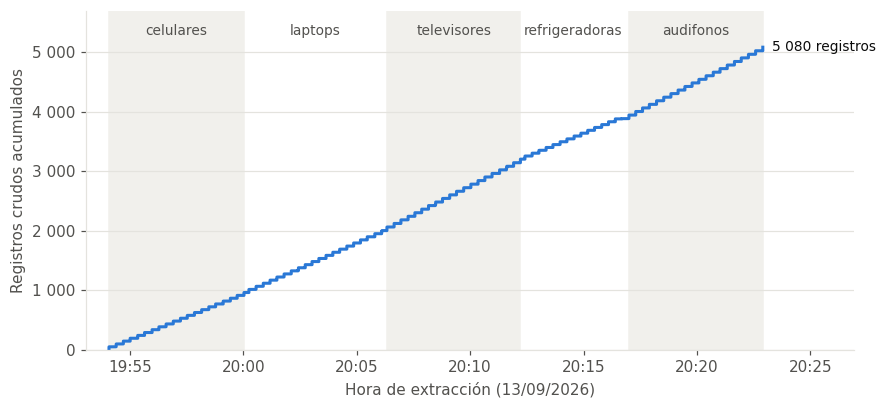

In [9]:
serie = crudo.sort_values("fecha_extraccion").reset_index(drop=True)
serie["acumulado"] = np.arange(1, len(serie) + 1)
tramos = serie.groupby("categoria")["fecha_extraccion"].agg(["min", "max"]).sort_values("min")

fig, ax = plt.subplots(figsize=(9, 4))
for i, (cat, fila) in enumerate(tramos.iterrows()):
    if i % 2 == 0:
        ax.axvspan(fila["min"], fila["max"], color="#f1f0ec", zorder=0)
    medio = fila["min"] + (fila["max"] - fila["min"]) / 2
    ax.text(medio, len(serie) * 1.03, cat, ha="center", va="bottom", fontsize=9, color=TEXTO_2)
ax.step(serie["fecha_extraccion"], serie["acumulado"], where="post", color=AZUL, linewidth=2, zorder=2)
ax.annotate(f"{len(serie):,} registros".replace(",", " "),
            xy=(serie["fecha_extraccion"].iloc[-1], len(serie)),
            xytext=(6, 0), textcoords="offset points", ha="left", va="center", fontsize=9, color=TEXTO)
ax.set_xlim(serie["fecha_extraccion"].min() - pd.Timedelta(minutes=1), serie["fecha_extraccion"].max() + pd.Timedelta(minutes=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.MinuteLocator(byminute=range(0, 60, 5)))
ax.yaxis.set_major_formatter(miles)
ax.set_ylim(0, len(serie) * 1.12)
ax.set_xlabel(f"Hora de extracción ({serie['fecha_extraccion'].dt.date.iloc[0]:%d/%m/%Y})")
ax.set_ylabel("Registros crudos acumulados")
ax.grid(axis="y")
ax.set_axisbelow(True)
guardar(fig, "progreso_extraccion.png")

In [10]:
EC1 = DATOS / "ec1_homeoffice"
ho_crudo = pd.read_csv(EC1 / "homeoffice_ml_crudo.csv", encoding="utf-8-sig")
ho_limpio = pd.read_csv(EC1 / "homeoffice_ml_limpio.csv", encoding="utf-8-sig")
assert ho_limpio["id_publicacion"].is_unique
nulos_ho = (ho_limpio.isna().mean() * 100).round(2)
excluidas_ho = nulos_ho[nulos_ho > 10].index.tolist()
ho_final = ho_limpio.drop(columns=excluidas_ho)
assert (ho_final.isna().mean() * 100).max() <= 10
ho_final.to_csv(EC1 / "homeoffice_final.csv", index=False, encoding="utf-8")
NOMBRES = {"laptops": "Laptop", "monitores": "Monitor", "sillas-de-oficina": "Silla de oficina",
           "teclados": "Teclado", "mouse": "Mouse", "audifonos": "Audífonos"}
len(ho_crudo), len(ho_limpio), ho_final.shape, excluidas_ho

(3680,
 2936,
 (2936, 13),
 ['precio_anterior', 'calificacion', 'opiniones', 'vendedor_texto'])

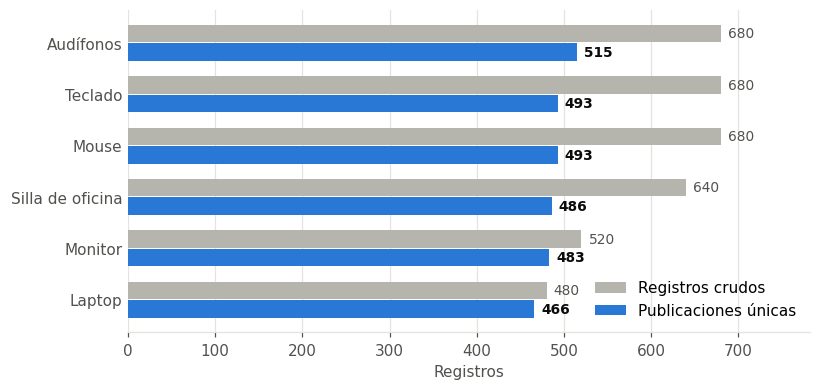

In [11]:
conteo_ho = pd.DataFrame({
    "crudo": ho_crudo["categoria"].value_counts(),
    "final": ho_final["categoria"].value_counts(),
}).rename(index=NOMBRES).sort_values("final")

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(conteo_ho))
ax.barh(y + 0.18, conteo_ho["crudo"], height=0.34, color=GRIS, label="Registros crudos")
ax.barh(y - 0.18, conteo_ho["final"], height=0.34, color=AZUL, label="Publicaciones únicas")
for yi, (c, f) in enumerate(zip(conteo_ho["crudo"], conteo_ho["final"])):
    ax.text(c + 8, yi + 0.18, str(c), va="center", fontsize=9, color=TEXTO_2)
    ax.text(f + 8, yi - 0.18, str(f), va="center", fontsize=9, color=TEXTO, fontweight="bold")
ax.set_yticks(y)
ax.set_yticklabels(conteo_ho.index)
ax.set_xlim(0, conteo_ho["crudo"].max() * 1.15)
ax.set_xlabel("Registros")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right")
guardar(fig, "ho_registros_por_componente.png")

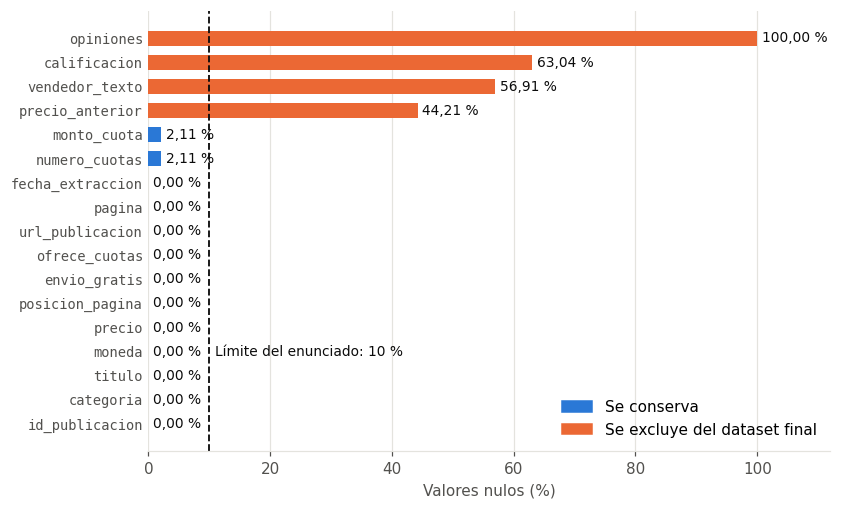

In [12]:
tabla_nulos = nulos_ho.sort_values().rename("porcentaje").reset_index().rename(columns={"index": "variable"})
fig, ax = plt.subplots(figsize=(8, 5.2))
colores_n = np.where(tabla_nulos["porcentaje"] > 10, NARANJA, AZUL)
ax.barh(tabla_nulos["variable"], tabla_nulos["porcentaje"], color=colores_n, height=0.62)
for yi, v in enumerate(tabla_nulos["porcentaje"]):
    ax.text(v + 0.8, yi, f"{v:.2f} %".replace(".", ","), va="center", fontsize=9, color=TEXTO)
ax.axvline(10, color=TEXTO, linewidth=1.2, linestyle="--")
ax.text(11, 3, "Límite del enunciado: 10 %", fontsize=9, color=TEXTO, va="center")
ax.set_xlim(0, 112)
ax.set_xlabel("Valores nulos (%)")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
for lbl in ax.get_yticklabels():
    lbl.set_fontfamily("DejaVu Sans Mono")
    lbl.set_fontsize(9)
handles = [plt.Rectangle((0, 0), 1, 1, color=AZUL), plt.Rectangle((0, 0), 1, 1, color=NARANJA)]
ax.legend(handles, ["Se conserva", "Se excluye del dataset final"], loc="lower right")
guardar(fig, "ho_nulos_por_columna.png")

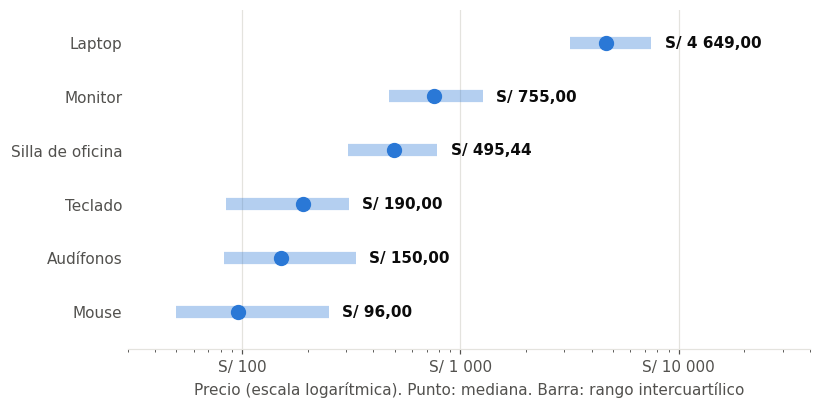

(                  ofertas       q1  mediana       q3
 categoria                                           
 Laptop                466  3192.25  4649.00  7499.00
 Monitor               483   470.00   755.00  1265.00
 Silla de oficina      486   306.80   495.44   784.75
 Teclado               493    84.30   190.00   309.00
 Audífonos             515    82.95   150.00   333.00
 Mouse                 493    49.90    96.00   250.00,
 np.float64(6335.44))

In [13]:
orden_ho = ["laptops", "monitores", "sillas-de-oficina", "teclados", "audifonos", "mouse"]
home_office = (ho_final.groupby("categoria")["precio"]
               .agg(ofertas="count", q1=lambda s: s.quantile(0.25), mediana="median", q3=lambda s: s.quantile(0.75))
               .loc[orden_ho].rename(index=NOMBRES))
costo_total = home_office["mediana"].sum()

fig, ax = plt.subplots(figsize=(8, 4))
ys = np.arange(len(home_office))[::-1]
for yi, fila in zip(ys, home_office.itertuples()):
    ax.hlines(yi, fila.q1, fila.q3, color=AZUL, linewidth=8, alpha=0.35)
    ax.plot(fila.mediana, yi, "o", color=AZUL, markersize=9)
    ax.text(fila.q3 * 1.15, yi, f"S/ {fila.mediana:,.2f}".replace(",", "X").replace(".", ",").replace("X", " "),
            va="center", fontsize=10, fontweight="bold", color=TEXTO)
ax.set_yticks(ys)
ax.set_yticklabels(home_office.index)
ax.set_ylim(-0.7, len(home_office) - 0.4)
ax.set_xscale("log")
ax.set_xlim(30, 40000)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"S/ {x:,.0f}".replace(",", " ")))
ax.set_xlabel("Precio (escala logarítmica). Punto: mediana. Barra: rango intercuartílico")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
guardar(fig, "costo_home_office.png")
home_office.round(2), round(costo_total, 2)

In [14]:
validacion = pd.DataFrame({
    "proyecto_13_09": limpio.groupby("categoria")["precio_actual"].median(),
    "ec1_15_09": ho_final.groupby("categoria")["precio"].median(),
}).loc[["laptops", "audifonos"]]
validacion["diferencia_pct"] = ((validacion["proyecto_13_09"] / validacion["ec1_15_09"] - 1) * 100).round(1)
validacion

,proyecto_13_09,ec1_15_09,diferencia_pct
categoria,,,
laptops,4898.5,4649.0,5.4
audifonos,138.0,150.0,-8.0


In [15]:
cuotas_ho = (ho_final.assign(cuotas=ho_final["numero_cuotas"].map({6: "6 cuotas", 12: "12 cuotas", 18: "18 cuotas"}).fillna("Sin información"))
             .groupby("categoria")["cuotas"].value_counts(normalize=True).mul(100).round(1).unstack(fill_value=0)
             .rename(index=NOMBRES))
fecha_ho = pd.to_datetime(ho_crudo["fecha_extraccion"])
cuotas_ho, fecha_ho.min(), fecha_ho.max(), ho_crudo["url_fuente"].nunique(), ho_crudo.groupby("categoria")["pagina"].max().to_dict()

(cuotas            12 cuotas  18 cuotas  6 cuotas  Sin información
 categoria                                                        
 Audífonos              16.5        0.2      82.9              0.4
 Laptop                 19.7        3.0      76.4              0.9
 Monitor                16.4        0.0      83.2              0.4
 Mouse                  18.5        0.0      76.1              5.5
 Silla de oficina       30.5        0.0      68.5              1.0
 Teclado                17.8        0.0      77.7              4.5,
 Timestamp('2026-09-15 23:34:39'),
 Timestamp('2026-09-15 23:44:02'),
 60,
 {'audifonos': 10,
  'laptops': 10,
  'monitores': 10,
  'mouse': 10,
  'sillas-de-oficina': 10,
  'teclados': 10})

In [16]:
sorted(p.name for p in FIGURAS.glob("*.png"))

['boxplot_precios_categoria.png',
 'costo_home_office.png',
 'cuotas_por_categoria.png',
 'embudo_limpieza.png',
 'ho_nulos_por_columna.png',
 'ho_registros_por_componente.png',
 'nulos_por_columna.png',
 'pipeline_extraccion.png',
 'progreso_extraccion.png',
 'registros_por_categoria.png']